In [2]:
!pip install -q transformers datasets accelerate scikit-learn


Cell 2 – Load dataset and preprocess

In [3]:
import pandas as pd
from datasets import load_dataset

reviews = load_dataset("SetFit/amazon_reviews_multi_en", split="train")

df = reviews.to_pandas()[["text", "label"]].drop_duplicates("text")

# Convert 5-star ratings into 3 sentiment classes
df["label"] = df["label"].map({
    0: 0,
    1: 0,
    2: 1,
    3: 2,
    4: 2
})

sentiments = ["Negative", "Neutral", "Positive"]

# Select 500 reviews from each class
df = df.groupby("label").sample(
    n=500, random_state=42
).reset_index(drop=True)

df["sentiment"] = df["label"].map(dict(enumerate(sentiments)))

print("Dataset shape:", df.shape)
print(df["sentiment"].value_counts())
display(df.head())

README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 47.4MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Dataset shape: (1500, 3)
sentiment
Negative    500
Neutral     500
Positive    500
Name: count, dtype: int64


,text,label,sentiment
0,Waste of money! Very flimsy. Broke after a wee...,0,Negative
1,Does not spin freely on the drone. Drone will ...,0,Negative
2,dislike clips are impossible to open you need ...,0,Negative
3,I got this handbag for Christmas. I loved the ...,0,Negative
4,A little larger than what I needed for phone a...,0,Negative


Cell 3 – Split dataset

In [4]:
from sklearn.model_selection import train_test_split

train_data, remaining = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_data, test_data = train_test_split(
    remaining,
    test_size=0.50,
    stratify=remaining["label"],
    random_state=42
)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Testing samples:", len(test_data))

Training samples: 1050
Validation samples: 225
Testing samples: 225


Cell 4 – Build and train LSTM model


In [5]:
import re
import torch
import torch.nn as nn

from collections import Counter
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report

torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# Create vocabulary from training reviews
counter = Counter(
    word
    for review in train_data["text"]
    for word in re.findall(r"[a-z']+", review.lower())
)

vocab = {
    word: i + 2
    for i, (word, _) in enumerate(counter.most_common(5000))
}

def convert_text(text, max_length=100):
    tokens = [
        vocab.get(word, 1)
        for word in re.findall(r"[a-z']+", text.lower())
    ][:max_length]

    return [0] * (max_length - len(tokens)) + tokens


def create_loader(data, shuffle=False):
    x = torch.tensor(
        [convert_text(t) for t in data["text"]],
        dtype=torch.long
    )

    y = torch.tensor(data["label"].values, dtype=torch.long)

    return DataLoader(
        TensorDataset(x, y),
        batch_size=32,
        shuffle=shuffle
    )


train_loader = create_loader(train_data, True)
val_loader = create_loader(val_data)
test_loader = create_loader(test_data)


class ReviewLSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(len(vocab) + 2, 100, padding_idx=0)
        self.lstm = nn.LSTM(100, 128, batch_first=True)
        self.output = nn.Linear(128, 3)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        return self.output(hidden[-1])


def get_predictions(model, loader):
    model.eval()
    predictions = []

    with torch.no_grad():
        for x, _ in loader:
            output = model(x.to(device))
            predictions.extend(output.argmax(1).cpu().tolist())

    return predictions


lstm_model = ReviewLSTM().to(device)

optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
loss_function = nn.CrossEntropyLoss()

best_accuracy = 0

for epoch in range(15):

    lstm_model.train()
    total_loss = 0

    for x, y in train_loader:

        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        output = lstm_model(x)
        loss = loss_function(output, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    predictions = get_predictions(lstm_model, val_loader)

    val_accuracy = accuracy_score(val_data["label"], predictions)

    print(
        f"Epoch {epoch+1}: Loss = {total_loss/len(train_loader):.3f}, "
        f"Validation Accuracy = {val_accuracy:.3f}"
    )

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_weights = {
            k: v.detach().clone()
            for k, v in lstm_model.state_dict().items()
        }

lstm_model.load_state_dict(best_weights)

lstm_predictions = get_predictions(lstm_model, test_loader)

print("\nLSTM Classification Report:\n")

print(classification_report(
    test_data["label"],
    lstm_predictions,
    target_names=sentiments
))

lstm_accuracy = accuracy_score(test_data["label"], lstm_predictions)

lstm_f1 = f1_score(
    test_data["label"],
    lstm_predictions,
    average="weighted"
)

Epoch 1: Loss = 1.099, Validation Accuracy = 0.369
Epoch 2: Loss = 1.042, Validation Accuracy = 0.400
Epoch 3: Loss = 0.949, Validation Accuracy = 0.444
Epoch 4: Loss = 0.804, Validation Accuracy = 0.453
Epoch 5: Loss = 0.609, Validation Accuracy = 0.462
Epoch 6: Loss = 0.413, Validation Accuracy = 0.444
Epoch 7: Loss = 0.242, Validation Accuracy = 0.453
Epoch 8: Loss = 0.129, Validation Accuracy = 0.436
Epoch 9: Loss = 0.106, Validation Accuracy = 0.458
Epoch 10: Loss = 0.044, Validation Accuracy = 0.498
Epoch 11: Loss = 0.021, Validation Accuracy = 0.458
Epoch 12: Loss = 0.012, Validation Accuracy = 0.467
Epoch 13: Loss = 0.007, Validation Accuracy = 0.462
Epoch 14: Loss = 0.004, Validation Accuracy = 0.484
Epoch 15: Loss = 0.003, Validation Accuracy = 0.476

LSTM Classification Report:

              precision    recall  f1-score   support

    Negative       0.45      0.31      0.37        75
     Neutral       0.42      0.36      0.39        75
    Positive       0.47      0.69   

Cell 5 – Load and tokenize BERT


In [6]:
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_reviews(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )


def prepare_dataset(data):
    dataset = Dataset.from_pandas(
        data[["text", "label"]],
        preserve_index=False
    )

    return dataset.map(tokenize_reviews, batched=True)


train_set = prepare_dataset(train_data)
val_set = prepare_dataset(val_data)
test_set = prepare_dataset(test_data)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1050 [00:00<?, ? examples/s]

Map:   0%|          | 0/225 [00:00<?, ? examples/s]

Map:   0%|          | 0/225 [00:00<?, ? examples/s]

Cell 6 – Fine-tune pre-trained BERT

In [7]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=3
)

training_args = TrainingArguments(
    output_dir="./sentiment_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=42
)


def calculate_accuracy(pred):
    labels = pred.label_ids
    predictions = pred.predictions.argmax(axis=1)

    return {
        "accuracy": accuracy_score(labels, predictions)
    }


trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_set,
    eval_dataset=val_set,
    compute_metrics=calculate_accuracy
)

trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.868636,0.657778
2,No log,0.789304,0.631111
3,No log,0.748276,0.684444


TrainOutput(global_step=198, training_loss=0.8241277367177636, metrics={'train_runtime': 26.1125, 'train_samples_per_second': 120.632, 'train_steps_per_second': 7.583, 'total_flos': 207201816460800.0, 'train_loss': 0.8241277367177636, 'epoch': 3.0})

Cell 7 – Test BERT model

In [8]:
bert_output = trainer.predict(test_set)

bert_predictions = bert_output.predictions.argmax(axis=1)

print("BERT Classification Report:\n")

print(classification_report(
    test_data["label"],
    bert_predictions,
    target_names=sentiments
))

bert_accuracy = accuracy_score(
    test_data["label"],
    bert_predictions
)

bert_f1 = f1_score(
    test_data["label"],
    bert_predictions,
    average="weighted"
)

BERT Classification Report:

              precision    recall  f1-score   support

    Negative       0.70      0.75      0.72        75
     Neutral       0.59      0.48      0.53        75
    Positive       0.75      0.84      0.79        75

    accuracy                           0.69       225
   macro avg       0.68      0.69      0.68       225
weighted avg       0.68      0.69      0.68       225



Cell 8 – Compare LSTM and BERT

Model  Accuracy  Weighted F1 Score
 LSTM    0.4533             0.4386
 BERT    0.6889             0.6815


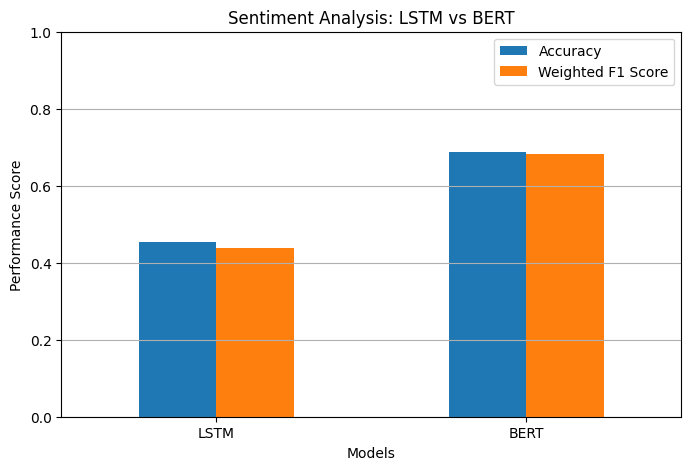

In [9]:
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["LSTM", "BERT"],
    "Accuracy": [lstm_accuracy, bert_accuracy],
    "Weighted F1 Score": [lstm_f1, bert_f1]
})

print(comparison.round(4).to_string(index=False))

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Sentiment Analysis: LSTM vs BERT")
plt.ylabel("Performance Score")
plt.xlabel("Models")
plt.grid(axis="y")
plt.show()